# Imports

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from seaborn import kdeplot
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
%matplotlib inline

# Dataset

In [44]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"
df = pd.read_csv(url)
df.to_csv("Clean laptop pricing data set", index= False)
df

,Unnamed: 0.1,Unnamed: 0,Manufacturer,Category,GPU,OS,CPU_core,Screen_Size_inch,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_pounds,Price,Price-binned,Screen-Full_HD,Screen-IPS_panel
0,0,0,Acer,4,2,1,5,14.0,0.551724,8,256,3.52800,978,Low,0,1
1,1,1,Dell,3,1,1,3,15.6,0.689655,4,256,4.85100,634,Low,1,0
2,2,2,Dell,3,1,1,7,15.6,0.931034,8,256,4.85100,946,Low,1,0
3,3,3,Dell,4,2,1,5,13.3,0.551724,8,128,2.69010,1244,Low,0,1
4,4,4,HP,4,2,1,7,15.6,0.620690,8,256,4.21155,837,Low,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233,233,233,Lenovo,4,2,1,7,14.0,0.896552,8,256,3.74850,1891,Medium,0,1
234,234,234,Toshiba,3,2,1,5,13.3,0.827586,8,256,2.64600,1950,Medium,1,0
235,235,235,Lenovo,4,2,1,5,12.0,0.896552,8,256,2.99880,2236,Medium,0,1
236,236,236,Lenovo,3,3,1,5,15.6,0.862069,6,256,5.29200,883,Low,1,0


# Simple linear regression

In [45]:
X = df[["CPU_frequency"]]
Y = df["Price"]
slm = LinearRegression() # slm = simple linear model
slm.fit(X,Y)
yhat = slm.predict(X)
yhat

array([1073.07834392, 1277.93263722, 1636.42765051, 1073.07834392,
       1175.50549057, 1073.07834392, 1073.07834392, 1073.07834392,
       1534.00050386, 1175.50549057, 1175.50549057, 1277.93263722,
       1277.93263722, 1073.07834392, 1073.07834392, 1534.00050386,
       1175.50549057, 1175.50549057, 1073.07834392, 1073.07834392,
       1175.50549057, 1534.00050386, 1175.50549057, 1534.00050386,
       1636.42765051, 1277.93263722, 1482.78693053, 1636.42765051,
       1636.42765051, 1534.00050386, 1636.42765051, 1636.42765051,
       1073.07834392, 1175.50549057, 1073.07834392, 1175.50549057,
       1636.42765051, 1175.50549057, 1534.00050386, 1073.07834392,
       1175.50549057, 1636.42765051, 1073.07834392, 1073.07834392,
       1073.07834392, 1687.64122384, 1073.07834392, 1534.00050386,
       1073.07834392, 1073.07834392,  868.22405061, 1175.50549057,
       1175.50549057, 1175.50549057, 1175.50549057, 1073.07834392,
       1073.07834392, 1534.00050386, 1636.42765051, 1534.00050

Regression plot

(0.0, 3974.15)

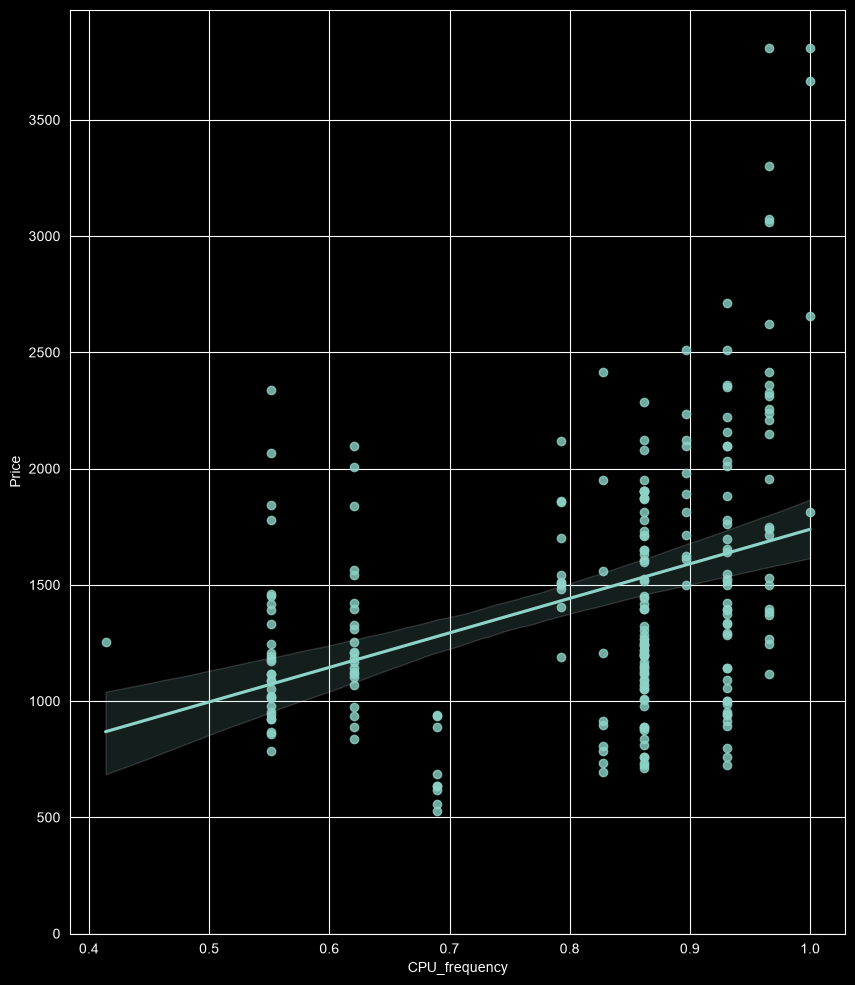

In [46]:
height = 10
width = 12
plt.figure(figsize = (height, width))
sns.regplot(x = X, y =  Y, data = df)
plt.ylim(0,)

Distribution plot

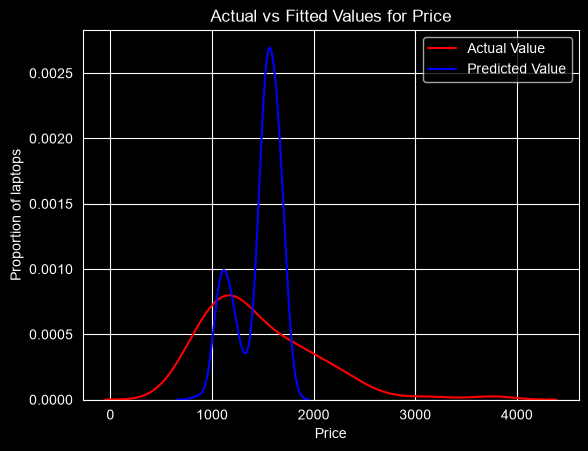

In [47]:
ax1 = sns.kdeplot(df["Price"], color = "r", label = "Actual value")
sns.kdeplot(yhat, color = "b", label = "Predicted value", ax=ax1)
plt.title('Actual vs Fitted Values for Price')
plt.xlabel('Price')
plt.ylabel('Proportion of laptops')
plt.legend(['Actual Value', 'Predicted Value'])
plt.show()

Evaluating R squared and MSE

In [48]:
print("The R squared of the SLR model is: \n", slm.score(X,Y))

print("The MSE of the SLR model is: \n", mean_squared_error(df["Price"],yhat))

The R squared of the SLR model is: 
 0.1344436321024326
The MSE of the SLR model is: 
 284583.4405868629


# Multiple linear regression

In [49]:
mlm = LinearRegression() #mlm = multiple linear model
Y = df["Price"]
predictor_MLR = df[["CPU_frequency","RAM_GB","Storage_GB_SSD","CPU_core","OS","GPU","Category"]]
mlm.fit(predictor_MLR, Y)
yhat_mlm = mlm.predict(predictor_MLR)
yhat_mlm

array([1345.51622771,  710.44905496, 1552.37242687, 1295.00681012,
       1543.13847022, 1056.42067418, 1252.02084839,  806.98504446,
       1007.51446753, 1449.64309091, 1254.0429167 ,  757.73972448,
        380.80382381, 1345.51622771, 1154.22076129, 1452.55027146,
       1445.33838312, 1254.0429167 , 1345.51622771, 1154.22076129,
       1640.93855733, 1452.55027146, 1543.13847022, 1167.75942573,
       1841.4679804 ,  283.00373671, 1212.25798099, 1552.37242687,
       1939.2680675 , 1376.73250015, 1939.2680675 , 1650.17251398,
       1345.51622771, 1449.64309091, 1154.22076129, 1543.13847022,
       1138.08329264, 1351.8430038 , 1105.31455464, 1056.42067418,
       1543.13847022, 1362.90546776,  882.80281577,  904.78513157,
       1056.42067418, 2093.00082524, 1252.02084839, 1643.84573788,
       1252.02084839, 1345.51622771, 1212.9253343 , 1449.64309091,
       1543.13847022, 1445.33838312, 1449.64309091, 1345.51622771,
        628.97535593, 1775.17253369, 1747.97260108, 1550.35035

Distribution plot

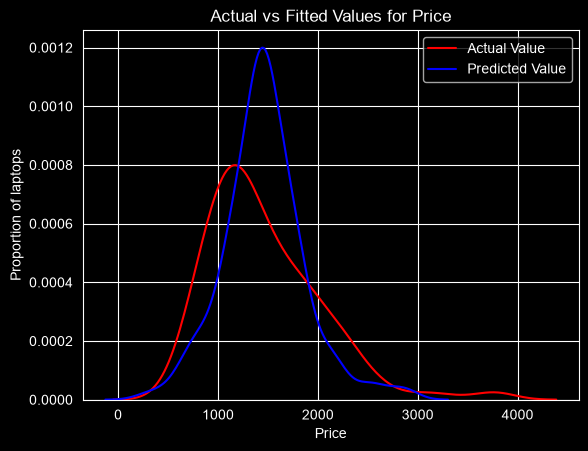

In [50]:
ax1 = sns.kdeplot(df["Price"], color = "r", label = "Actual price")
sns.kdeplot(yhat_mlm, color = "b", label = "Predicted prices", ax = ax1)

plt.title('Actual vs Fitted Values for Price')
plt.xlabel('Price')
plt.ylabel('Proportion of laptops')
plt.legend(['Actual Value', 'Predicted Value'])
plt.show()

R squared and MSE

In [51]:
print("The R squared of the SLR model is: \n", mlm.score(predictor_MLR,Y))

print("The MSE of the SLR model is: \n", mean_squared_error(df["Price"],yhat_mlm))

The R squared of the SLR model is: 
 0.5082509055187376
The MSE of the SLR model is: 
 161680.57263893104


# Polynomial Regerssion

In [52]:
X = X.to_numpy().flatten()
f1 = np.polyfit(X, Y, 1)
p1 = np.poly1d(f1)

f3 = np.polyfit(X, Y, 3)
p3 = np.poly1d(f3)

f5 = np.polyfit(X, Y, 5)
p5 = np.poly1d(f5)

In [53]:
def PlotPolly(model, independent_variable, dependent_variabble, Name):
    x_new = np.linspace(independent_variable.min(),independent_variable.max(),100)
    y_new = model(x_new)

    plt.plot(independent_variable, dependent_variabble, '.', x_new, y_new, '-')
    plt.title(f'Polynomial Fit for Price ~ {Name}')
    ax = plt.gca()
    ax.set_facecolor((0.898, 0.898, 0.898))
    fig = plt.gcf()
    plt.xlabel(Name)
    plt.ylabel('Price of laptops')

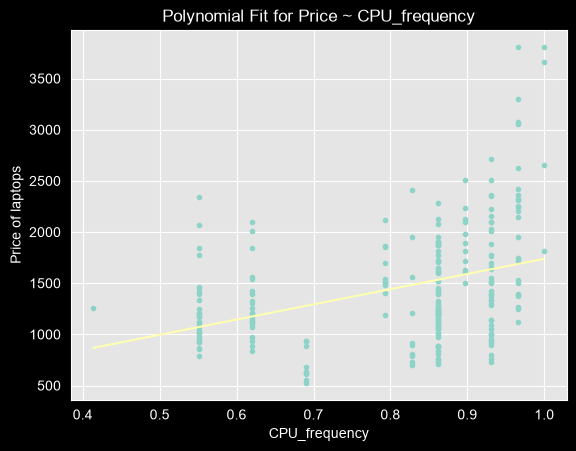

In [54]:
PlotPolly(p1, X, Y, 'CPU_frequency')

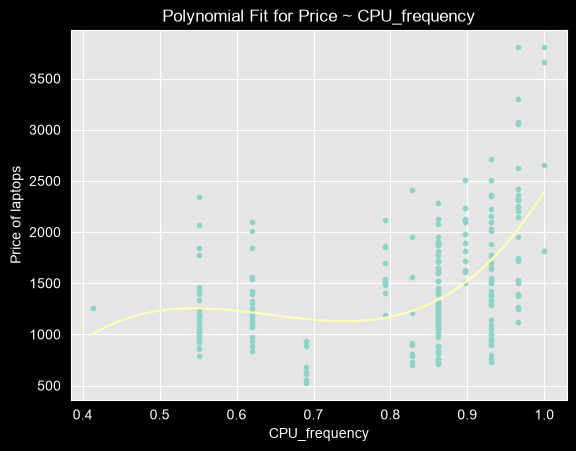

In [55]:
PlotPolly(p3, X, Y, 'CPU_frequency')

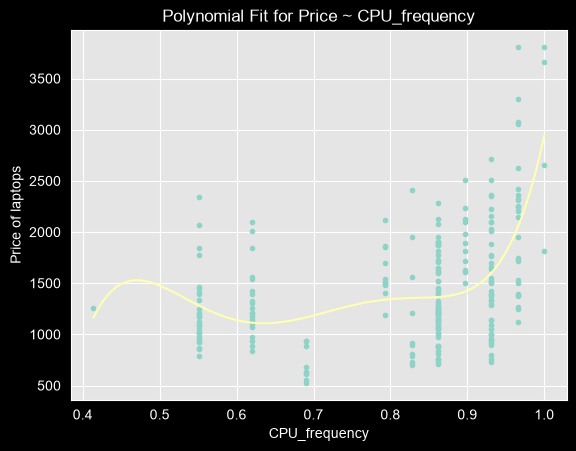

In [56]:
PlotPolly(p5, X, Y, 'CPU_frequency')

In [57]:
r_squared_1 = r2_score(Y, p1(X))
print('The R square value for 1st degree polynomial is: ', r_squared_1)
print('The MSE value for 1st degree polynomial is: ', mean_squared_error(Y,p1(X)))
r_squared_3 = r2_score(Y, p3(X))
print('The R square value for 3rd degree polynomial is: ', r_squared_3)
print('The MSE value for 3rd degree polynomial is: ', mean_squared_error(Y,p3(X)))
r_squared_5 = r2_score(Y, p5(X))
print('The R square value for 5th degree polynomial is: ', r_squared_5)
print('The MSE value for 5th degree polynomial is: ', mean_squared_error(Y,p5(X)))

The R square value for 1st degree polynomial is:  0.1344436321024326
The MSE value for 1st degree polynomial is:  284583.4405868629
The R square value for 3rd degree polynomial is:  0.2669264079653113
The MSE value for 3rd degree polynomial is:  241024.86303848765
The R square value for 5th degree polynomial is:  0.3030822706443915
The MSE value for 5th degree polynomial is:  229137.29548053455
